#### Reyhan Anindya Untoro 39-256147 
#### Methods of Aquatic Biology Report Assignment

# Data Analysis with Python and Generative AI

For this assignment, I am using the data that I'm going to analyze the data I will be using for my master's research. The theme of my research is to find out the effect of oxygen minimum zones on the fisheries in the Seto Inland Sea area. Therefore, the first step of research is to analyze the available water quality data of the seto inland sea area, mainly the dissolved oxygen data (DO).

The goal is to create a water quality dataset that can be used for further analysis down the line in my research progress. My current goals for the data analysis are as follows: 

1. Combine and sort, and filter all of the available water quality data into one master data set.
2. create a visualization of the DO level distribution across all of the available year from the sampling data, divideded by the different seasons.
3. Plot the yearly total hypoxic area from all the water mass area grouped by the different seasons.
4.Calculate the yearly total hypoxic area for summer bottom data grouped by the different water mass.

# Materials and Methods

The data that I'm using for this analysis was sourced from the official website from the ministry of environment Japan. link: https://water-pub.env.go.jp/water-pub/mizu-site/mizu/download/download.asp

I used Visual Studio code (VS Code) as the code editor application. Within VS code I installed Jupyter Notebook as an extention for the notebook interface to write and edit my python code for the analysis. I also use Google Gemini AI and Github copilot extention on VS code to get insight on how to write the code for the analysis I need and also troubleshoot any errors I encounter on my analysis process.

The first step of my analysis is to download all of the data from the previous website. This website provides the data from all of the water area of Japan. However I only downloaded the data for my study area which is the Seto Inland Sea and Osaka Bay Area from 1981 to 2022 (41 years). The website provides the data in three different format, but I choose to download the data in shapefile format (shp) because it is the best data format option to be used for geospatial analysis. This is because shp file format contains geographical data such as coordinates and has a coordinate reference system that can be used to perform a spatioal joint analysis.

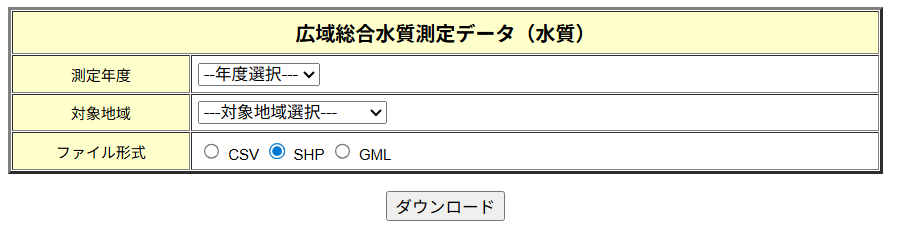

After downloading the file, I proceed with my data sorting and analysis in python. The steps of my analysis process are as follows: 

1. combining all of the files into one master geo-data frame named merged_gdf. This will be the main data source that I will be using for the remainder of the analysis.
2. Creating extra columns such as the water mass divisions and seasons.
3. Sorting the data based on the bottom layer data only. 
4. Defining global parameters for downstream analysis (vmin, vmax, years).
5. Performing variogram analysis to find out the decorrelation distance to be used for interpolation.
6. Plotting the yearly seaasonal map of the DO distribution and combining them into a gif animation.
7. Calculating and plotting the yearly total hypoxic area for every season.
8. Calculating and plotting the yearly total hypoxic area for summer bottom data grouped by water masses.

## Results

Below are the final code that are used for all of the steps of my analysis, along with their output and results.

In [16]:
import pandas as pd
import geopandas as gpd
import os

# --- Load Water Mass Codes ---
# Load the manual and correctly rename the columns
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)
codes_df = codes_df.rename(columns={
    'Water Mass Code': 'watercode',
    'Water Mass Name': 'watermass_name',
    'Water Mass Division': 'division',
    'Water Mass Details': 'details'
}) #[cite: 41, 44-49]

# --- Load and Combine Yearly Environmental Data ---
base_data_path = '../data/raw/environmental_data' #[cite: 159]
gdfs = []
for dirpath, _, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames: #[cite: 164, 165]
        # Extract year from the folder name
        try:
            year = int(os.path.basename(dirpath).split('_')[0]) #[cite: 168]
        except (ValueError, IndexError):
            continue
        
        # Read shapefile, add year, and append to list
        shp_filepath = os.path.join(dirpath, 'output.shp') #[cite: 171]
        gdf_temp = gpd.read_file(shp_filepath) #[cite: 172]
        gdf_temp['year'] = year #[cite: 173]
        gdfs.append(gdf_temp) #[cite: 174]

# Concatenate all yearly data into one GeoDataFrame
all_points_gdf = pd.concat(gdfs, ignore_index=True) #[cite: 177]
print(f"Loaded and combined {len(all_points_gdf)} data points from {len(gdfs)} files.")

Loaded and combined 41346 data points from 84 files.


In [17]:
# --- Merge Datasets ---
# Ensure 'watercode' columns are the same integer type before merging
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int) #[cite: 270]
codes_df['watercode'] = codes_df['watercode'].astype(int) #[cite: 270]
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left') #[cite: 277]

# --- Create Season Column ---
def get_season(month): #[cite: 548]
    """Takes a month (1-12) and returns the corresponding season.""" #[cite: 549]
    if month in [12, 1, 2]: return 'Winter' #[cite: 550]
    elif month in [3, 4, 5]: return 'Spring' #[cite: 551]
    elif month in [6, 7, 8, 9]: return 'Summer' #[cite: 552]
    elif month in [10, 11]: return 'Autumn' #[cite: 553]
    else: return 'Unknown' #[cite: 556]

merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season) #[cite: 557]

# --- Final Cleanup ---
# Ensure 'do_' column is a numeric type for calculations
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce') #[cite: 688]

print("Data merged and 'season' column created successfully.")
print(f"Merged dataset contains {len(merged_gdf)} records.")
print(merged_gdf[['year', 'surveymont', 'season', 'division']].head()) #[cite: 561]

Data merged and 'season' column created successfully.
Merged dataset contains 41346 records.
   year  surveymont  season   division
0  1981           5  Spring  Osaka Bay
1  1981           8  Summer  Osaka Bay
2  1981           1  Winter  Osaka Bay
3  1981           5  Spring  Osaka Bay
4  1981           8  Summer  Osaka Bay


In [18]:
# Filter for summer bottom-layer data with valid DO measurements
analysis_df = merged_gdf[
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(f"Prepared {len(analysis_df)} data points for analysis.")
print(analysis_df.columns)
print(analysis_df[['year', 'surveymont', 'season', 'saisuipoin', 'do_']].head())

Prepared 20631 data points for analysis.
Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year',
       'watermass_name', 'division', 'details', 'season'],
      dtype='object')
    year  surveymont  season  saisuipoin  do_
3   1981           5  Spring           2  4.4
4   1981           8  Summer           2  3.9
5   1981          10  Autumn           2  4.2
6   1981          

In [19]:
vmin = analysis_df['do_'].min()
vmax = analysis_df['do_'].max()
print(f"DO range: {vmin} to {vmax}")

# Check for any remaining NaNs in 'do_' or geometry
if analysis_df['do_'].isnull().any():
    print("Warning: Still NaN values in 'do_' after initial dropna.")
if analysis_df['geometry'].isnull().any():
    print("Warning: Still NaN values in 'geometry' after initial dropna.")

# define global parameters for DO maps
years = sorted(analysis_df['year'].unique())

DO range: 0.1 to 13.0


Data for variogram: 499 valid points
DO dtype: float64

Calculated Decorrelation Length (D value) at 1/e: 0.2326 degrees
(approximately: 25.8948 kilometers)


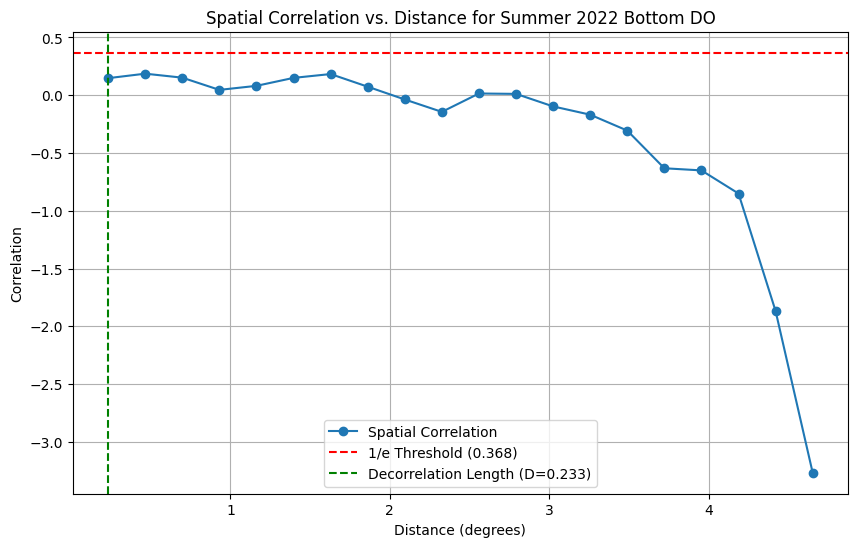

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import skgstat as skg

# --- Use data from a representative time period to find a characteristic k ---
# For example, let's use the summer data from a single, data-rich year (e.g., 2022)
data_for_k = analysis_df[analysis_df['year'] == 2022].copy()

# **SAFETY CHECK: Ensure do_ is numeric and drop NaNs for variogram calculation**
data_for_k['do_'] = pd.to_numeric(data_for_k['do_'], errors='coerce')
data_for_k = data_for_k.dropna(subset=['do_'])

print(f"Data for variogram: {len(data_for_k)} valid points")
print(f"DO dtype: {data_for_k['do_'].dtype}")


# 1. Create the Variogram object
#    coords are the geometry points, values are the DO measurements
V = skg.Variogram(
    coordinates=np.column_stack((data_for_k.geometry.x, data_for_k.geometry.y)),
    values=data_for_k['do_'].values,
    n_lags=20 # A common, robust model
)

# Extract the distance bins and the variance (dissimilarity) for each bin
distances = V.bins
variances = V.experimental

# --- 3. Convert Variance to Correlation ---
# We can approximate correlation: corr ≈ 1 - (normalized variance)
# The 'sill' of the variogram is the background variance of the data.
sill = np.var(data_for_k['do_'].values)
correlations = 1 - (variances / sill)

# --- 4. Find the Decorrelation Length (k) ---
# Find the first distance where the correlation drops below 1/e
threshold = 1 / (np.e) 
decorrelation_mask = correlations < threshold
if np.any(decorrelation_mask):
    D_parameter = distances[decorrelation_mask][0]
else:
    D_parameter = distances[-1]

# Convert D_parameter from degrees to kilometers
D_parameter_km = D_parameter * 111.32

print(f"\nCalculated Decorrelation Length (D value) at 1/e: {D_parameter:.4f} degrees")
print(f"(approximately: {D_parameter_km:.4f} kilometers)")

# --- 5. Plot the Results for Verification ---
plt.figure(figsize=(10, 6))
plt.plot(distances, correlations, marker='o', linestyle='-', label='Spatial Correlation')
plt.axhline(y=threshold, color='r', linestyle='--', label=f'1/e Threshold ({threshold:.3f})')
plt.axvline(x=D_parameter, color='g', linestyle='--', label=f'Decorrelation Length (D={D_parameter:.3f})')
plt.xlabel('Distance (degrees)')
plt.ylabel('Correlation')
plt.title('Spatial Correlation vs. Distance for Summer 2022 Bottom DO')
plt.legend()
plt.grid(True)
plt.show()

Figure 1: Spatial correlation vs. Distance for Summer 2022 Bottom DO. This plot shows the calculated spatial correlation of dissolved oxygen (DO) values plotted against distance (in degrees). This variogram analysis was used to determine the decorrelation length (D=0.233 degrees) , which is the distance at which the correlation drops below the 1/e threshold (0.368). This parameter was used for the spatial interpolation in subsequent analyses.

Saved frame for 2022 to ../reports/figures/seasonal_gif_frames\frame_2022.png


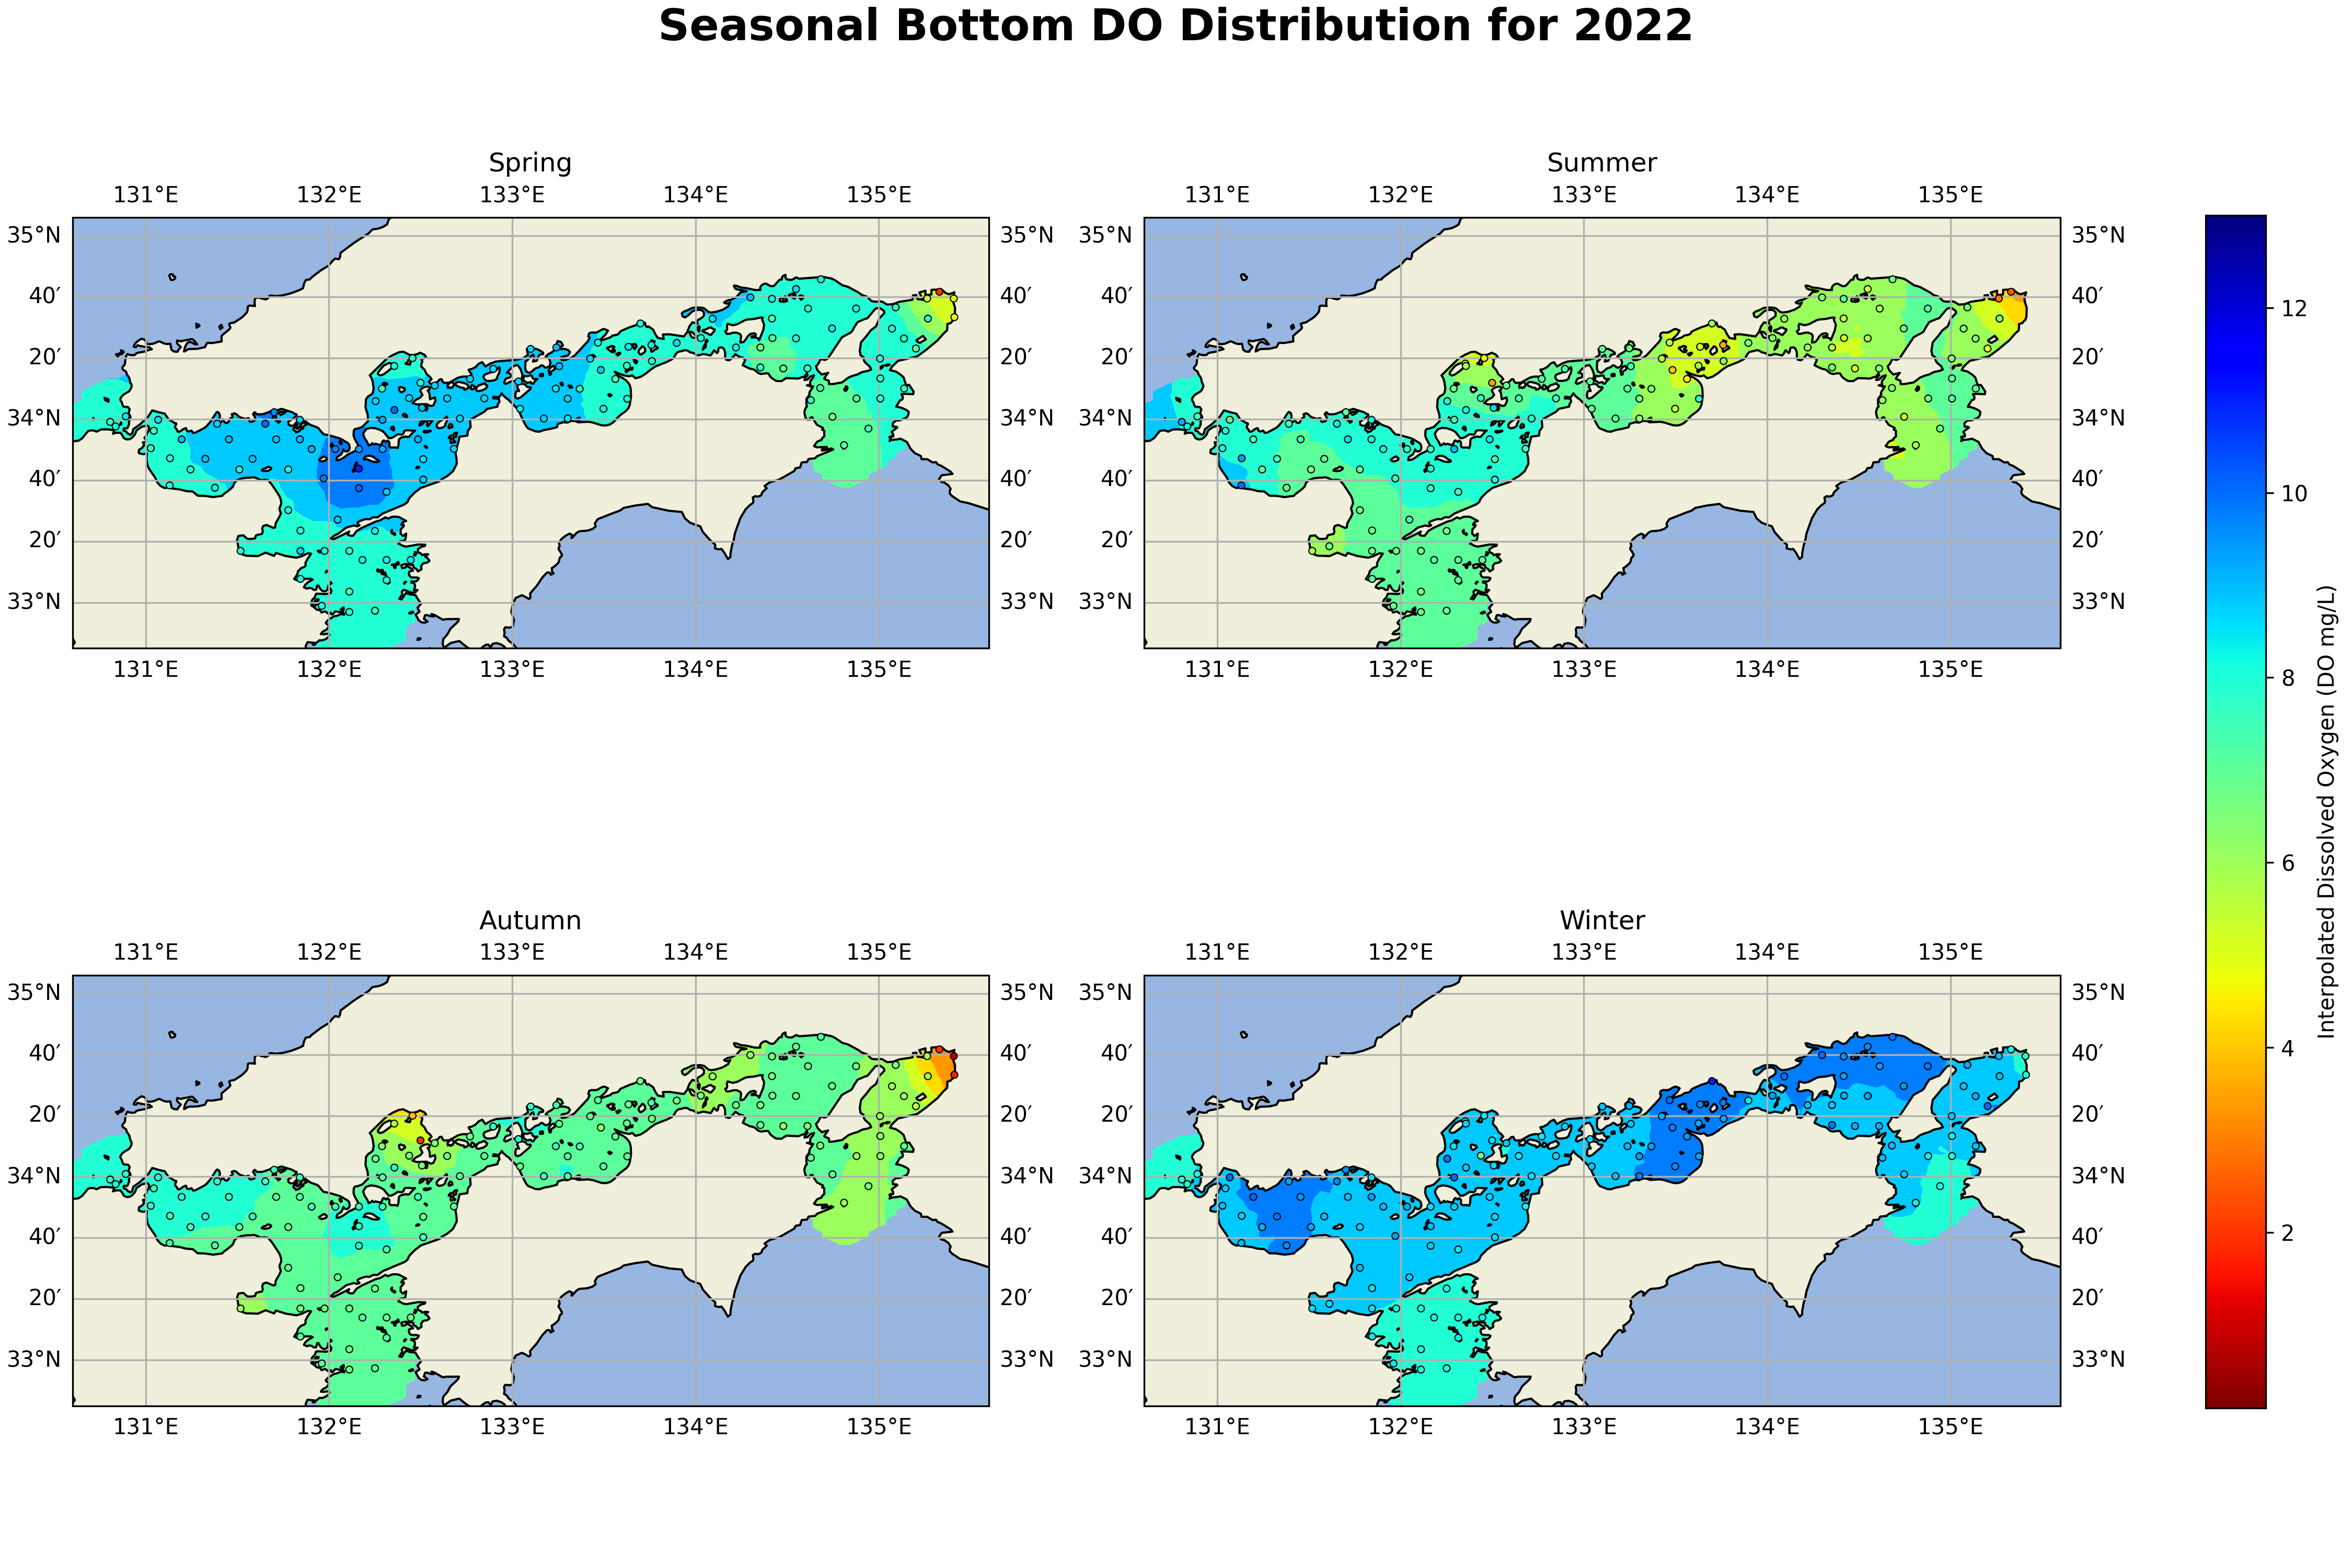

In [21]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.cm as cm
import matplotlib.colors as colors
from scipy.interpolate import griddata
from scipy.spatial.distance import cdist

def create_seasonal_maps_for_year(year, data, vmin, vmax, output_dir):
    """
    Generates and saves a 2x2 grid of seasonal DO heatmaps for a given year.
    """
    # --- Create the 2x2 subplot figure ---
    fig, axes = plt.subplots(
        2, 2, figsize=(15, 10),
        subplot_kw={'projection': ccrs.PlateCarree()},
        constrained_layout=True
    )
    fig.suptitle(f'Seasonal Bottom DO Distribution for {year}', fontsize=20, fontweight='bold')
    # Flatten the 2x2 axes array for easy iteration
    axes = axes.flatten()
    
    # Store the last contour plot to use for the single, shared colorbar
    last_contour = None
    seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
    extent = [130.6, 135.6, 32.75, 35.1]
    grid_res_x, grid_res_y = (100j, 100j)

    # --- Inner loop to create a map for each season ---
    for i, season in enumerate(seasons):
        ax = axes[i]
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.OCEAN, zorder=0)
        ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, zorder=3)
        ax.set_title(season)

        # Filter data for the specific year AND season
        year_season_data = data[
            (data['year'] == year) &
            (data['season'] == season)
        ]
        
        if len(year_season_data) > 3:
            # --- Interpolation ---
            measured_coords = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
            measured_values = year_season_data['do_'].values
            grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y]
            target_coords = np.array([grid_x.flatten(), grid_y.flatten()]).T

            # --- Apply Distance-Weighted Interpolation ---
            distances = cdist(target_coords, measured_coords)
            weights = np.exp(-((distances / D_parameter)**2))
            weights[distances > D_parameter] = 0

            # Compute the weighted averages
            sum_of_weights = np.sum(weights, axis=1)
            weighted_sum_of_values = np.sum(weights * measured_values[np.newaxis, :], axis=1)
    
            estimated_do = np.full(target_coords.shape[0], np.nan)
            valid_indices = sum_of_weights > 1e-6
            estimated_do[valid_indices] = weighted_sum_of_values[valid_indices] / sum_of_weights[valid_indices]
    
            grid_z = estimated_do.reshape(grid_x.shape)

            # --- Plotting the heatmap ---
            contour = ax.contourf(
                grid_x, grid_y, grid_z,
                levels=np.linspace(vmin, vmax, 15),
                cmap='jet_r', vmin=vmin, vmax=vmax,
                transform=ccrs.PlateCarree(), zorder=1
            )
            last_contour = contour

            # --- FIX: Plot the original data points on top for context ---
            ax.scatter(
                year_season_data.geometry.x,
                year_season_data.geometry.y,
                c=year_season_data['do_'],        # Color points based on this column
                cmap='jet_r',
                vmin=vmin, vmax=vmax,
                edgecolor='black',
                linewidth=0.5,
                transform=ccrs.PlateCarree(),
                s=10,                     # Point size
                zorder=3                   # Draw on the very top layer
            )
        else:
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes, ha='center', va='center', fontsize=15)
    
        # --- PRESERVE STYLE: Draw Land and Coastlines on TOP of the heatmap ---
        ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
        #ax.add_feature(cfeature.COASTLINE, zorder=2)
        
    # --- PRESERVE STYLE: Add a single colorbar for the whole figure ---
    if last_contour:
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        mappable = cm.ScalarMappable(norm=norm, cmap='jet_r')
        cbar = fig.colorbar(mappable, ax=axes, orientation='vertical', fraction=0.03, pad=0.04)
        cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)')

    # Save the composite figure for the year
    output_path = os.path.join(output_dir, f'frame_{year}.png')
    plt.savefig(output_path, dpi=300) # Removed bbox_inches='tight' for consistency
    plt.close(fig)
    print(f"Saved frame for {year} to {output_path}")

# --- Setup your parameters once ---
output_dir = '../reports/figures/seasonal_gif_frames'
os.makedirs(output_dir, exist_ok=True)
years = sorted(analysis_df['year'].unique())

# --- Call the function for a single year to test ---
test_year = 2022
create_seasonal_maps_for_year(test_year, analysis_df, vmin, vmax, output_dir)

# show the saved file
from IPython.display import Image
Image(filename=f'../reports/figures/seasonal_gif_frames/frame_{test_year}.png')

Figure 2: Seasonal Bottom DO Distribution for 2022. This 2x2 grid shows the interpolated spatial distribution of bottom layer dissolved oxygen (DO) for the Seto Inland Sea during 2022, separated by season (Spring, Summer, Autumn, Winter). The heatmaps are interpolated from the sampling data points, which are shown as small dots .

In [22]:
# In [9]: Hypoxia Area Calculation
# --- 1. Setup ---
hypoxic_threshold = 2.0 # DO level in mg/L
results = []
extent = [130.6, 135.6, 32.75, 35.1]
grid_res_x, grid_res_y = (100j, 100j) # Match resolution used in plotting

# Approx cell area calculation (consider using projected CRS for better accuracy if needed)
center_latitude = np.mean([extent[2], extent[3]])
lat_dist = 111 # Approx km per degree latitude
lon_dist = np.cos(np.radians(center_latitude)) * 111.32 # Approx km per degree longitude
cell_area_km2 = ((extent[1] - extent[0]) / (grid_res_x.imag - 1)) * lon_dist * \
                 ((extent[3] - extent[2]) / (grid_res_y.imag - 1)) * lat_dist

seasons = ['Winter', 'Spring', 'Summer', 'Autumn']

# --- 2. Loop Through Data to Calculate Hypoxic Area ---
print("\n--- Calculating Hypoxic Area ---")
for year in years:
    for season in seasons:
        year_season_data = analysis_df[
            (analysis_df['year'] == year) &
            (analysis_df['season'] == season)
        ]
        
        if len(year_season_data) < 4:
            hypoxic_area = np.nan # Use NaN if not enough data
        else:
            points = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
            values = year_season_data['do_'].values
            grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y]
            try:
                # Use 'nearest' interpolation for a more direct count based on observed lows
                grid_z = griddata(points, values, (grid_x, grid_y), method='nearest') 
                
                # Count cells below threshold (ignoring NaNs from interpolation)
                hypoxic_cells = np.nansum(grid_z < hypoxic_threshold)
                hypoxic_area = hypoxic_cells * cell_area_km2
            except Exception as e:
                 print(f"    Hypoxia calculation failed for {year} {season}: {e}")
                 hypoxic_area = np.nan # Mark as NaN on error

        results.append({
            'year': year,
            'season': season,
            'hypoxic_area_km2': hypoxic_area
        })

# --- 3. Create DataFrame ---
hypoxia_df = pd.DataFrame(results)
print("Hypoxia analysis complete. Preview:")
print(hypoxia_df.head())
# Optional: Save results
# hypoxia_df.to_csv('../data/processed/hypoxia_results.csv', index=False)


# In [10]: Check Minimum DO Values (Verification)
min_do_by_season = analysis_df.groupby('season')['do_'].min()
print("\nMinimum DO value observed (in filtered bottom layer data) for each season:")
print(min_do_by_season)


--- Calculating Hypoxic Area ---
Hypoxia analysis complete. Preview:
   year  season  hypoxic_area_km2
0  1981  Winter          0.000000
1  1981  Spring       1929.836118
2  1981  Summer          0.000000
3  1981  Autumn          0.000000
4  1982  Winter          0.000000

Minimum DO value observed (in filtered bottom layer data) for each season:
season
Autumn    0.7
Spring    0.5
Summer    0.1
Winter    1.0
Name: do_, dtype: float64


Plotting hypoxic area trends over time...


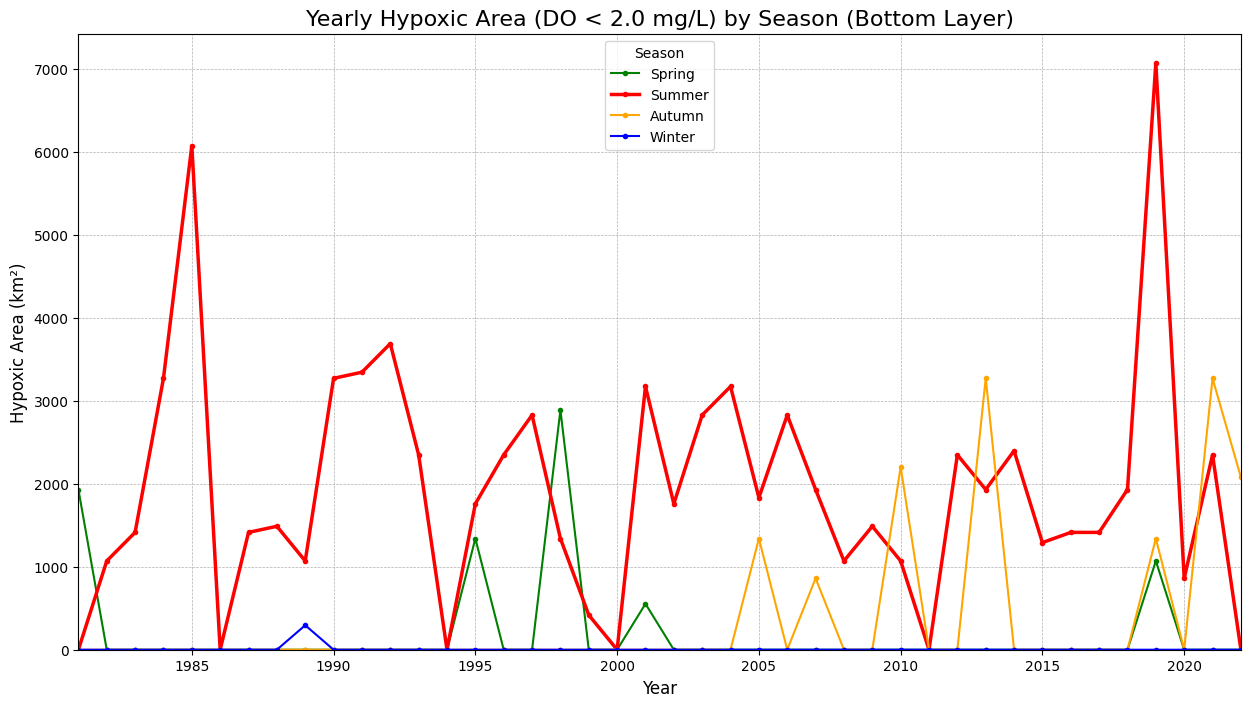

In [23]:
# Plot the yearly seasonal total hypoxic area

print("Plotting hypoxic area trends over time...")

# --- 1. Pivot the DataFrame ---
# To plot this easily, we need 'year' as the index and seasons as columns.
hypoxia_pivot_df = hypoxia_df.pivot(
    index='year',
    columns='season',
    values='hypoxic_area_km2'
)

# Re-order the columns to a logical seasonal order
seasons_ordered = ['Spring', 'Summer', 'Autumn', 'Winter']
hypoxia_pivot_df = hypoxia_pivot_df[seasons_ordered]

# --- 2. Create the Plot ---
plt.figure(figsize=(15, 8))

# Define colors for clarity
colors = {
    'Spring': 'green',
    'Summer': 'red',
    'Autumn': 'orange',
    'Winter': 'blue'
}

# Plot each season's line
for season in seasons_ordered:
    plt.plot(
        hypoxia_pivot_df.index,
        hypoxia_pivot_df[season],
        label=season,
        marker='.',
        linestyle='-',
        color=colors[season],
        # Make the 'Summer' line thicker to stand out
        linewidth=2.5 if season == 'Summer' else 1.5
    )

# --- 3. Add Labels and Titles ---
plt.title('Yearly Hypoxic Area (DO < 2.0 mg/L) by Season (Bottom Layer)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Hypoxic Area (km²)', fontsize=12)
plt.legend(title='Season', fontsize=10)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

# Set x-axis limits to span all years clearly
plt.xlim(hypoxia_pivot_df.index.min(), hypoxia_pivot_df.index.max())
# Set y-axis to start at 0
plt.ylim(bottom=0)

plt.show()

Figure 3: Yearly Hypoxic Area (DO < 2.0 mg/L) by Season (Bottom Layer). A time-series line plot showing the total calculated hypoxic area (in km²) from 1981 to 2022. Each line represents a different season , highlighting that significant hypoxia occurs almost exclusively during the summer.

Calculating hypoxic area for 42 years and 12 water masses...
Calculation complete. Pivoted data preview:
division  Aki Nada  Bingo Nada  Bisan Seto  Bungo Channel  Harima Nada  \
year                                                                     
1981           0.0         0.0         0.0            0.0          0.0   
1982           0.0         0.0         0.0            0.0          0.0   
1983           0.0         0.0         0.0            0.0          0.0   
1984           0.0         0.0         0.0            0.0          0.0   
1985           0.0         0.0         0.0            0.0          0.0   

division  Hibiki Nada  Hiroshima Bay  Hiuchi Nada  Iyo Nada  Kii Channel  \
year                                                                       
1981              0.0            0.0          0.0       0.0          0.0   
1982              0.0            0.0          0.0       0.0          0.0   
1983              0.0            0.0          0.0       0.0          0.0

<Figure size 1800x900 with 0 Axes>

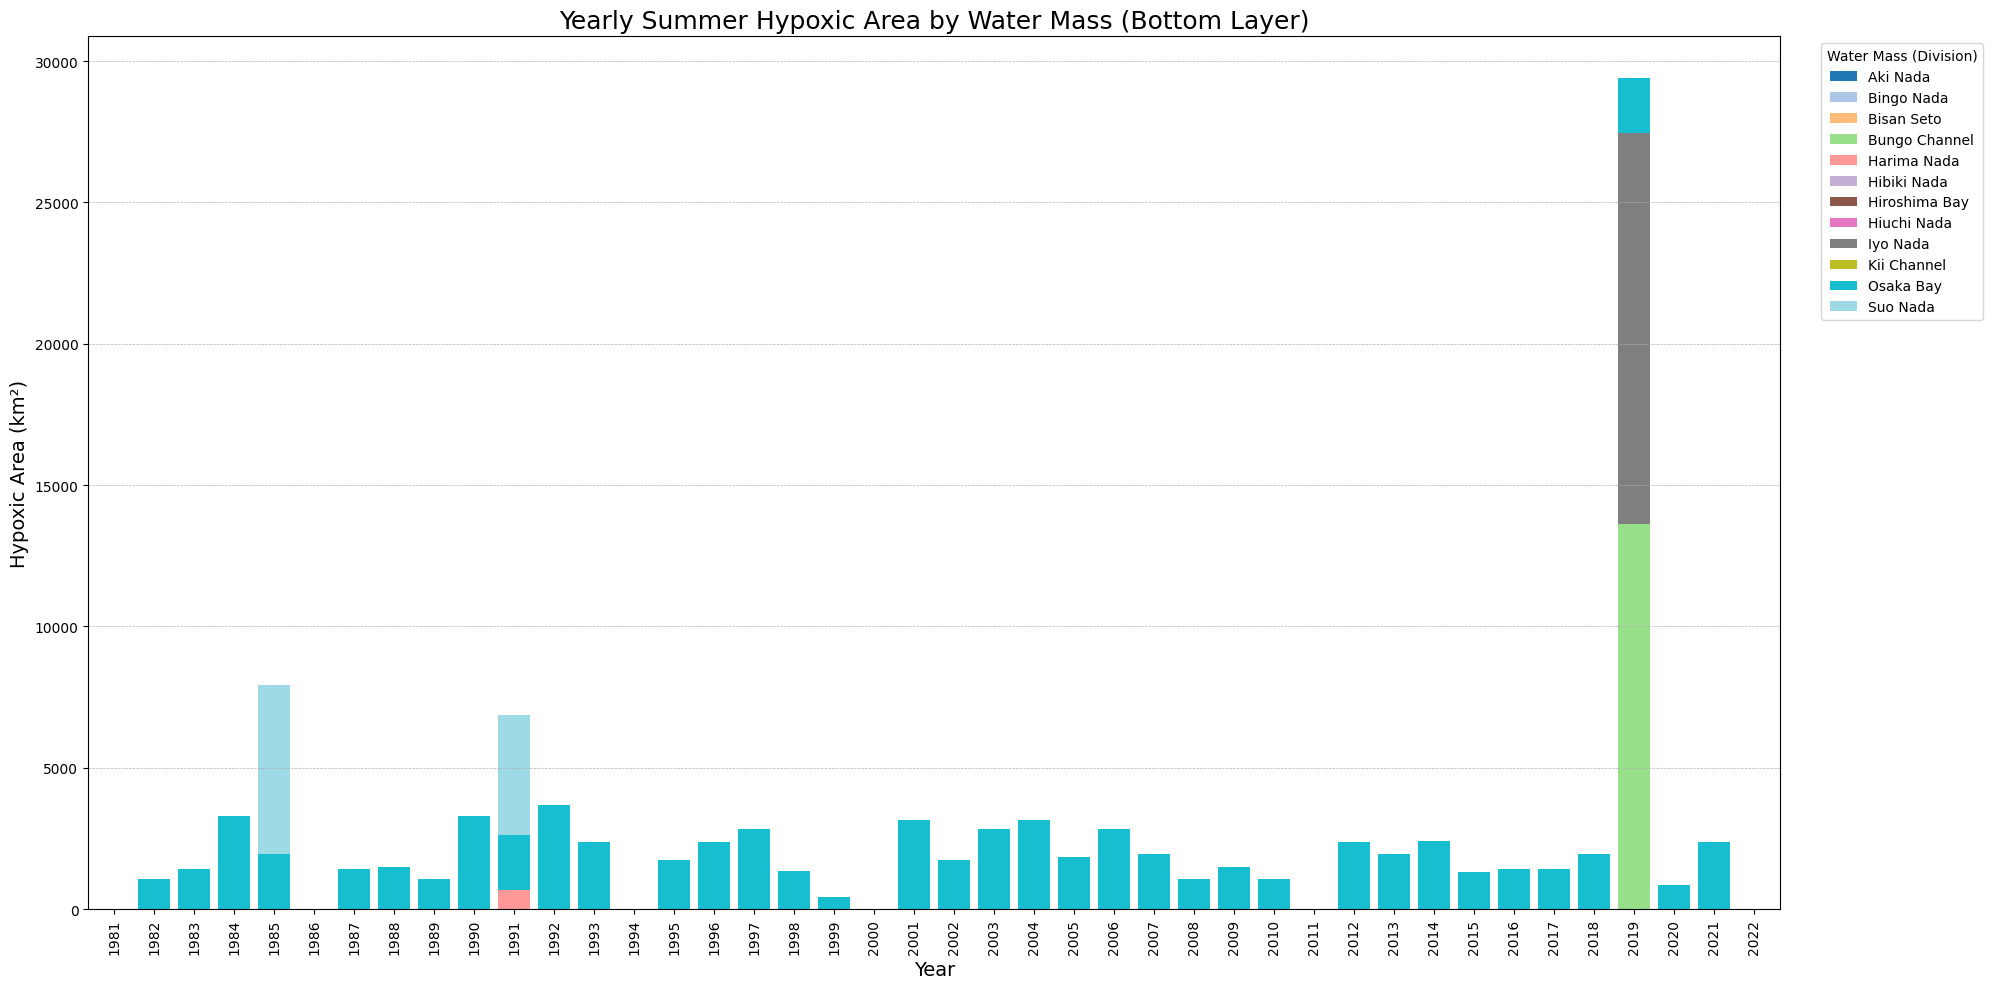

In [24]:
# Plot the yearly hypoxic area of the different water masses

# --- 1. Filter data ---

summer_bottom_df = analysis_df[
    (analysis_df['season'] == 'Summer')
].copy()

years_to_process = sorted(summer_bottom_df['year'].unique())
divisions_to_process = summer_bottom_df['division'].unique()

# In [13]: Calculate and Plot Hypoxic Area by Water Mass

# --- 1. Setup Constants (from your cell In [10]) ---
hypoxic_threshold = 2.0  # [cite: 564]
extent = [130.6, 135.6, 32.75, 35.1]  # [cite: 566]
grid_res_x, grid_res_y = (100j, 100j)  # [cite: 567]

# Approx cell area calculation (re-using your logic from In [10]) [cite: 568-570]
center_latitude = np.mean([extent[2], extent[3]])
lat_dist = 111  # Approx km per degree Latitude
lon_dist = np.cos(np.radians(center_latitude)) * 111.32 # Approx km per degree Long
cell_area_km2 = ((extent[1] - extent[0]) / (grid_res_x.imag - 1)) * lon_dist * \
                ((extent[3] - extent[2]) / (grid_res_y.imag - 1)) * lat_dist

# Get unique years and divisions from our summer data
years_to_process = sorted(summer_bottom_df['year'].unique())
divisions_to_process = summer_bottom_df['division'].unique()

print(f"Calculating hypoxic area for {len(years_to_process)} years and {len(divisions_to_process)} water masses...")

# --- 2. Loop Through Data to Calculate Hypoxic Area ---
division_results = []

for year in years_to_process:
    for division in divisions_to_process:
        
        # Filter for this specific year AND division
        year_division_data = summer_bottom_df[
            (summer_bottom_df['year'] == year) &
            (summer_bottom_df['division'] == division)
        ]
        
        hypoxic_area = np.nan # Default to NaN
        
        # We need at least 4 points for interpolation [cite: 579]
        if len(year_division_data) >= 4:
            
            # Get points (coordinates) and values (DO)
            points = np.array([year_division_data.geometry.x, year_division_data.geometry.y]).T # [cite: 582]
            values = year_division_data['do_'].values # [cite: 582]
            
            # Define the grid
            grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y] # [cite: 583]
            
            try:
                # Use 'nearest' interpolation (same as In [10]) [cite: 584]
                grid_z = griddata(points, values, (grid_x, grid_y), method='nearest')
                
                # Count cells below threshold [cite: 585]
                hypoxic_cells = np.nansum(grid_z < hypoxic_threshold)
                hypoxic_area = hypoxic_cells * cell_area_km2 # [cite: 586]
                
            except Exception as e:
                # This catches errors on interpolation for small/collinear datasets
                hypoxic_area = np.nan # [cite: 588]
        
        division_results.append({
            'year': year,
            'division': division,
            'hypoxic_area_km2': hypoxic_area
        })

# --- 3. Create DataFrame and Pivot ---
hypoxia_by_division_df = pd.DataFrame(division_results)

# Pivot for plotting: index=year, columns=division, values=area
hypoxia_division_pivot = hypoxia_by_division_df.pivot(
    index='year',
    columns='division',
    values='hypoxic_area_km2'
).fillna(0) # Fill NaNs with 0 for stacking

print("Calculation complete. Pivoted data preview:")
print(hypoxia_division_pivot.head())

# --- 4. Plot the Stacked Bar Chart ---
# A stacked bar chart is perfect for this
plt.figure(figsize=(18, 9))

# Use a colormap that is good for distinct categories
# 'tab20' has 20 distinct colors. If you have more divisions, 'tab20b' or 'tab20c' are options.
num_divisions = len(divisions_to_process)
cmap = cm.get_cmap('tab20' if num_divisions <= 20 else 'viridis', num_divisions)

hypoxia_division_pivot.plot(
    kind='bar', 
    stacked=True, 
    figsize=(20, 10), 
    cmap=cmap,
    width=0.8
)

plt.title('Yearly Summer Hypoxic Area by Water Mass (Bottom Layer)', fontsize=18)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Hypoxic Area (km²)', fontsize=14)

# Place legend outside the plot to keep it clean
plt.legend(title='Water Mass (Division)', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.tight_layout() # Adjusts plot to prevent legend from being cut off
plt.show()

Figure 4: Yearly Summer Hypoxic Area by Water Mass (Bottom Layer). A stacked bar chart illustrating the total hypoxic area (km²) during the summer season for each year from 1981 to 2022. Each bar is segmented by color to show the relative contribution of each water mass "division" (e.g., Osaka Bay, Harima Nada) to the total hypoxic area for that year .

## Discussion

The result of my analysis confirmed the findings from my litterature review. A sample frame of the yearly seasonal DO distribution (Figure 2) Shows that DO levels are high during late spring and summer and low during winter. Figure 3 also shows that the hypoxic water masses mainly formed durring summer every year. This is because during summer, surface water heating occurs which causes the water to be stratified. This will then cause the bottom layer of water to be oxygen deficient because the oxygen supply from the surface is cut off (Diaz 2008).

The last analysis have also managed to show which water masses are the most affected areas by hypoxia during summer. According to figure 4, these areas are Osaka Bay, Harima Nada, and Hiuchi Nada, shown by their largest proportions in the bar chart. However, figure 4 also shows a peculiar spike during 2019 compared to all of the other years. This might be caused by either an error somewhere in the data analysis process. Another reason might be the analysis is correct, and this result might be a sign that shows an extreme event which happened during that year which cause this increase in total hypoxic area. Further analysis is required to confirm both this hypothesis.

The next step of my research is to move on to analyzing the fisheries data and connect the results with the results in this water quality data analysis.

## References

1. Ministry of Environment, Japan. (2024). Public Water Area Water Quality Measurement Data. Retrieved November 8, 2025, from [https://water-pub.env.go.jp/water-pub/mizu-site/mizu/download/download.asp](https://water-pub.env.go.jp/water-pub/mizu-site/mizu/download/download.asp)
2. Diaz, R. J., & Rosenberg, R. (2008). Spreading Dead Zones and Consequences for Marine Ecosystems. Science, 321(5891), 926–929. https://doi.org/10.1126/science.1156401

## Appendix (examples of the prompts I used to write the code)

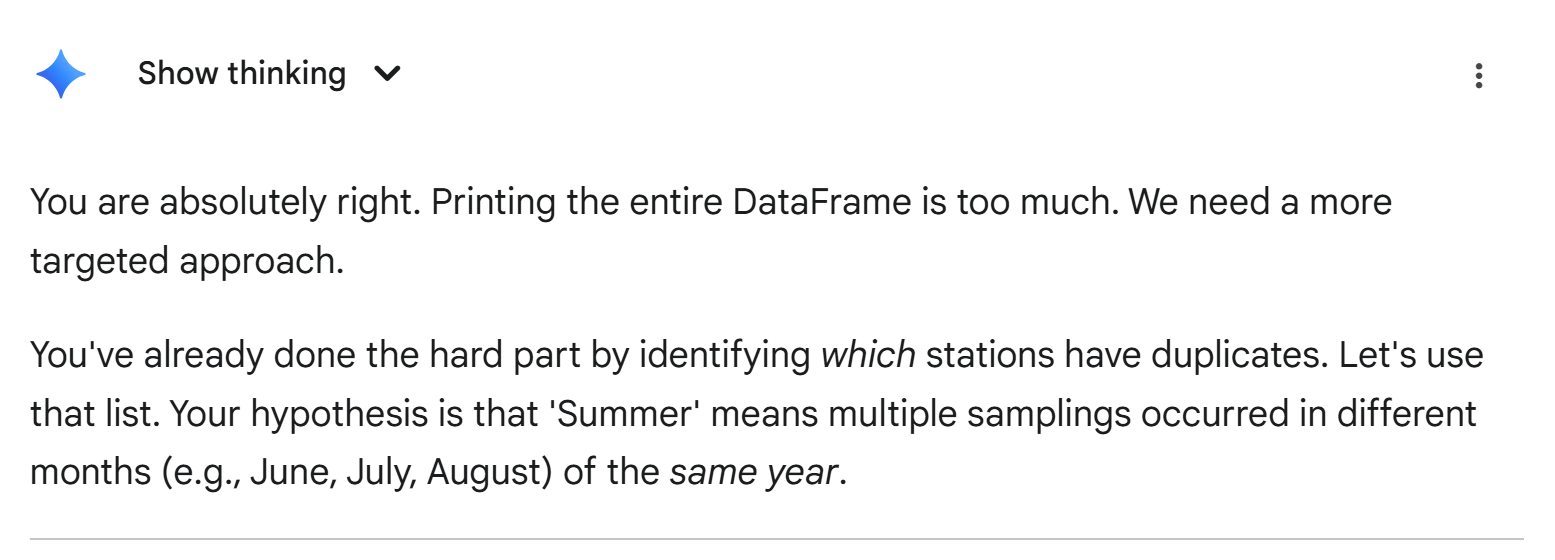|

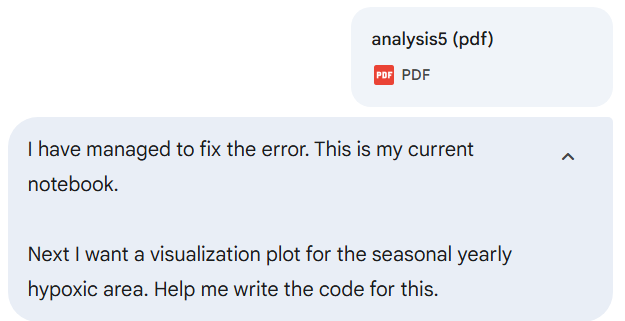
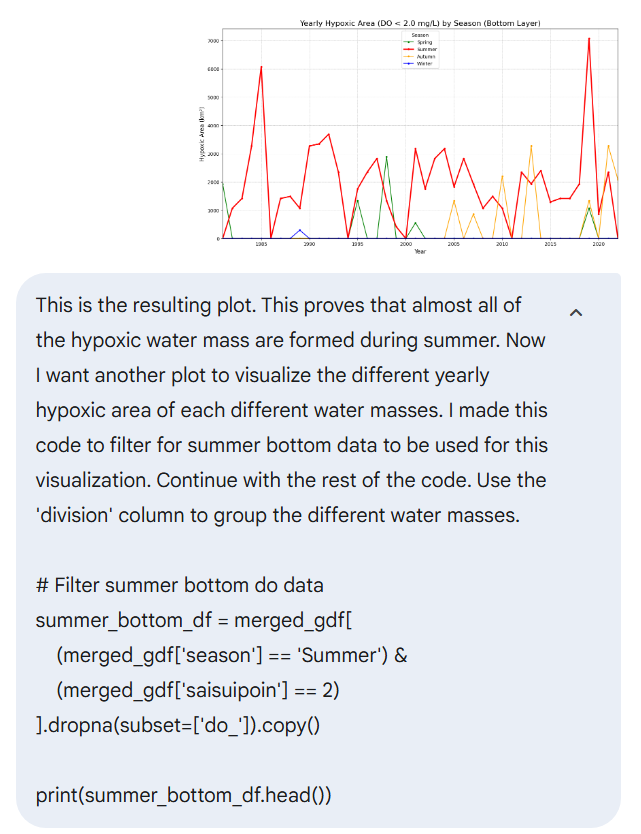